# Implement the techniques of the precedent notebook

Training a neural network involves more than just running gradient descent. Several techniques can dramatically affect how fast the network learns, how well it generalises to unseen data, and whether it gets stuck or diverges.

This notebook explores the most important ones using a **synthetic regression dataset** built from a combination of trigonometric and logarithmic functions with added Gaussian noise.

## 1. Synthetic Dataset

Import the required libraries:

In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

Generate 1000 evenly-spaced points over $[0, 4\pi]$ and compute the target function:

$$y_{\text{true}}(x) = \sin(x) + 0.5\cos(2x) + 0.3\ln(x+1)$$

Then add Gaussian noise $\varepsilon \sim \mathcal{N}(0,\, 0.2^2)$ to simulate real-world measurements:

$$y_{\text{noisy}}(x) = y_{\text{true}}(x) + \varepsilon$$

In [26]:
np.random.seed(42)

x       = np.linspace(0, 4 * np.pi, 1000)
y_true  = np.sin(x) + 0.5 * np.cos(2 * x) + 0.3 * np.log(x + 1)
noise   = np.random.normal(0, 0.2, size=x.shape)
y_noisy = y_true + noise

df = pd.DataFrame({'x': x, 'y_true': y_true, 'y_noisy': y_noisy})
df.head()

,x,y_true,y_noisy
0,0.000000,0.500000,0.599343
1,0.012579,0.516171,0.488518
2,0.025158,0.531976,0.661514
3,0.037737,0.547417,0.852023
4,0.050316,0.562492,0.515662


## 2. Train / Validation / Test Split

In [27]:
from sklearn.model_selection import train_test_split

X = df[['x']].values
y = df['y_noisy'].values.reshape(-1, 1)

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=42)
X_val,   X_test,  y_val,  y_test  = train_test_split(X_temp, y_temp, test_size=0.50, random_state=42)

print(f'Train: {X_train.shape[0]}  |  Val: {X_val.shape[0]}  |  Test: {X_test.shape[0]}')

Train: 700  |  Val: 150  |  Test: 150


## 3. Input Normalisation

In [28]:
# Use the training set statistics to normalize all sets
mu    = X_train.mean()
sigma = X_train.std()

X_train_n = (X_train - mu) / sigma
X_val_n   = (X_val   - mu) / sigma
X_test_n  = (X_test  - mu) / sigma

print(f'Train mean: {X_train_n.mean():.4f}  std: {X_train_n.std():.4f}')
print(f'Val mean: {X_val_n.mean():.4f}  std: {X_val_n.std():.4f}')
print(f'Test mean: {X_test_n.mean():.4f}  std: {X_test_n.std():.4f}')

Train mean: -0.0000  std: 1.0000
Val mean: 0.0408  std: 1.0207
Test mean: -0.0483  std: 1.0160


## 4. Perform He initialization

In [29]:
def init_params(layer_sizes, seed=0):
    np.random.seed(seed)
    params = {}
    for i in range(1, len(layer_sizes)):
        fan_in = layer_sizes[i - 1]
        params[f'W{i}'] = np.random.randn(fan_in, layer_sizes[i]) * np.sqrt(2 / fan_in)
        params[f'b{i}'] = np.zeros((1, layer_sizes[i]))
    return params

layer_sizes = [1, 64, 128, 64, 1]
params = init_params(layer_sizes)
print({k: v.shape for k, v in params.items()})

{'W1': (1, 64), 'b1': (1, 64), 'W2': (64, 128), 'b2': (1, 128), 'W3': (128, 64), 'b3': (1, 64), 'W4': (64, 1), 'b4': (1, 1)}


## 5. Train baseline

In [30]:
def relu(z):      
    return np.maximum(0, z)

def relu_deriv(z):  
    return (z > 0).astype(float)

In [31]:
def forward(X, params):
    cache = {'a0': X}
    a = X
    n_layers = len(params) // 2

    for i in range(1, n_layers):        # hidden layers — ReLU
        z = a @ params[f'W{i}'] + params[f'b{i}']
        a = relu(z)
        cache[f'z{i}'] = z
        cache[f'a{i}'] = a

    i = n_layers                        # output layer — linear
    z = a @ params[f'W{i}'] + params[f'b{i}']
    cache[f'z{i}'] = z
    cache[f'a{i}'] = z
    
    return z, cache

In [32]:
def backward(y, y_hat, params, cache):
    m = y.shape[0]
    grads = {}
    n_layers = len(params) // 2
    delta = -(y - y_hat) / m

    for i in range(n_layers, 0, -1):
        grads[f'dW{i}'] = cache[f'a{i-1}'].T @ delta
        grads[f'db{i}'] = delta.sum(axis=0, keepdims=True)

        if i > 1:
            delta = delta @ params[f'W{i}'].T * relu_deriv(cache[f'z{i-1}'])
            
    return grads

In [33]:
def update_params(params, grads, lr):
    for key in params:
        params[key] -= lr * grads['d' + key]
        
    return params

In [34]:
def mse(y, y_hat):
    return np.mean((y - y_hat) ** 2)

In [35]:
import time

def train(X_tr, y_tr, X_v, y_v, layer_sizes, lr=1e-2, epochs=2000, seed=0):
    params = init_params(layer_sizes, seed=seed)
    train_loss, val_loss = [], []

    start = time.time()
    for _ in range(epochs):
        y_hat, cache = forward(X_tr, params)
        grads        = backward(y_tr, y_hat, params, cache)
        params       = update_params(params, grads, lr)
        train_loss.append(mse(y_tr, y_hat))
        y_hat_v, _   = forward(X_v, params)
        val_loss.append(mse(y_v, y_hat_v))
    end = time.time()

    elapsed = end - start
    print(f'Final train MSE: {train_loss[-1]:.4f}  |  val MSE: {val_loss[-1]:.4f}  |  time: {elapsed:.2f}s')
    return params, train_loss, val_loss, elapsed

In [36]:
params_base, tl_base, vl_base, t_base = train(
    X_train_n, y_train, X_val_n, y_val,
    layer_sizes=[1, 64, 128, 64, 1], lr=1e-2, epochs=2000
)


Final train MSE: 0.2536  |  val MSE: 0.2196  |  time: 26.65s


## 6. Improved Network

Five techniques are layered on top of the baseline:

| Technique | Details |
|---|---|
| **L2 regularisation** | Adds $\frac{\lambda}{2m}\sum\|W\|_F^2$ to the cost; shrinks weights and reduces overfitting |
| **Dropout** | Randomly zeros hidden neurons with probability $1-p_{\text{keep}}$, then rescales survivors by $1/p_{\text{keep}}$ (inverted dropout) |
| **Data augmentation** | Adds small Gaussian noise to training inputs at every epoch, increasing effective dataset diversity |
| **Early stopping** | Monitors validation MSE; halts training and restores the best checkpoint when no improvement is seen for `patience` epochs |
| **LR decay** | $\alpha_t = \dfrac{\alpha_0}{1 + d\cdot t}$ — large updates early, fine-grained steps near convergence |

> **Architecture note** — Regularisation combats overfitting. A small network like `[1,32,32,1]` barely overfits the baseline, so stacking L2 + dropout + augmentation only pushes it into underfitting. The improved version uses `[1,64,128,64,1]`: large enough to overfit without regularisation, but the techniques keep it in check. Each regulariser is also intentionally mild (`λ=0.001`, `keep_prob=0.95`) — piling them all at full strength would recreate the same problem.

> **Why not log loss?** Binary cross-entropy is designed for *classification* (sigmoid outputs, binary labels). This is a regression task with continuous targets, so MSE remains the right loss. L2 regularisation is added directly to MSE to penalise large weights.


**Inverted dropout** zeroes each hidden unit with probability $1 - p_{\text{keep}}$, then scales surviving activations up by $1/p_{\text{keep}}$ so the expected activation magnitude is unchanged. No correction is needed at inference time.

In [37]:
def forward_dropout(X, params, keep_prob=0.95, training=True):
    """Forward pass with inverted dropout on hidden layers."""
    cache = {'a0': X}
    a = X
    n_layers = len(params) // 2

    for i in range(1, n_layers):            # hidden layers — ReLU + dropout
        z = a @ params[f'W{i}'] + params[f'b{i}']
        a = relu(z)
        if training:
            mask = (np.random.rand(*a.shape) < keep_prob)
            a    = a * mask / keep_prob      # inverted dropout: scale up surviving units
            cache[f'mask{i}'] = mask
        cache[f'z{i}'] = z
        cache[f'a{i}'] = a

    i = n_layers                             # output layer — linear, no dropout
    z = a @ params[f'W{i}'] + params[f'b{i}']
    cache[f'z{i}'] = z
    cache[f'a{i}'] = z
    return z, cache


The regularised cost adds the squared Frobenius norm of every weight matrix:

$$J_{\text{reg}} = \underbrace{\frac{1}{m}\sum(y - \hat{y})^2}_{\text{MSE}} + \underbrace{\frac{\lambda}{2m}\sum_l \|W^{(l)}\|_F^2}_{\text{L2 penalty}}$$

Its gradient w.r.t. $W^{(l)}$ gets an extra $\frac{\lambda}{m}W^{(l)}$ term. The dropout mask is re-applied during the backward pass so the gradient only flows through neurons that were *active* in the forward pass.

In [38]:
def mse_l2(y, y_hat, params, lambd=0.001):
    """MSE + L2 weight penalty."""
    m        = y.shape[0]
    n_layers = len(params) // 2
    l2       = sum(np.sum(params[f'W{i}'] ** 2) for i in range(1, n_layers + 1))
    return np.mean((y - y_hat) ** 2) + (lambd / (2 * m)) * l2


def backward_l2_dropout(y, y_hat, params, cache, lambd=0.001, keep_prob=0.95):
    """Backward pass with L2 regularisation and inverted-dropout gradient."""
    m        = y.shape[0]
    grads    = {}
    n_layers = len(params) // 2
    delta    = -(y - y_hat) / m

    for i in range(n_layers, 0, -1):
        grads[f'dW{i}'] = cache[f'a{i-1}'].T @ delta + (lambd / m) * params[f'W{i}']
        grads[f'db{i}'] = delta.sum(axis=0, keepdims=True)

        if i > 1:
            delta = delta @ params[f'W{i}'].T
            if f'mask{i-1}' in cache:          # propagate only through active neurons
                delta = delta * cache[f'mask{i-1}'] / keep_prob
            delta = delta * relu_deriv(cache[f'z{i-1}'])

    return grads


**Data augmentation** injects a fresh noise perturbation into the training inputs at every epoch. This is the 1-D analogue of random cropping/flipping in image tasks: the network never sees exactly the same training example twice, which implicitly regularises it.

**Early stopping** keeps a running checkpoint of the best weights and restores them at the end, so the returned model corresponds to the epoch with the lowest validation MSE.

In [39]:
def augment_data(X, noise_std=0.02):
    """Add Gaussian noise to training inputs (data augmentation)."""
    return X + np.random.normal(0, noise_std, size=X.shape)


def train_improved(X_tr, y_tr, X_v, y_v, layer_sizes,
                   lr0=1e-2, epochs=5000, seed=0,
                   lambd=0.001, keep_prob=0.95,
                   decay_rate=3e-4, patience=500,
                   noise_std=0.01):
    params      = init_params(layer_sizes, seed=seed)
    train_loss, val_loss = [], []
    best_val    = np.inf
    best_params = None
    wait        = 0

    start = time.time()
    for epoch in range(epochs):
        lr    = lr0 / (1 + decay_rate * epoch)           # ① LR decay
        X_aug = augment_data(X_tr, noise_std=noise_std)  # ② data augmentation

        # ③ forward with dropout  ④ backward with L2
        y_hat, cache = forward_dropout(X_aug, params, keep_prob=keep_prob, training=True)
        grads        = backward_l2_dropout(y_tr, y_hat, params, cache,
                                           lambd=lambd, keep_prob=keep_prob)
        params       = update_params(params, grads, lr)

        # Evaluate in inference mode (dropout disabled)
        y_hat_tr, _ = forward_dropout(X_tr, params, training=False)
        y_hat_v,  _ = forward_dropout(X_v,  params, training=False)
        train_loss.append(mse(y_tr, y_hat_tr))   # pure MSE — comparable to baseline
        vl = mse(y_v, y_hat_v)
        val_loss.append(vl)

        # ⑤ early stopping
        if vl < best_val - 1e-6:
            best_val    = vl
            best_params = {k: v.copy() for k, v in params.items()}
            wait        = 0
        else:
            wait += 1
            if wait >= patience:
                print(f'Early stopping at epoch {epoch + 1}  '
                      f'(best val MSE: {best_val:.4f})')
                break

    elapsed = time.time() - start
    print(f'Final train loss: {train_loss[-1]:.4f}  |  '
          f'val MSE: {val_loss[-1]:.4f}  |  time: {elapsed:.2f}s')
    return best_params, train_loss, val_loss, elapsed


In [40]:
# Same architecture, same seed — only regularisation differs.
# Key lessons from tuning:
#  • keep_prob=0.95 (very light dropout: enough signal, less noise on val)
#  • decay_rate=3e-4 (slow decay so LR is still useful at epoch 3000+)
#  • patience=500    (dropout makes val loss noisy — need more patience)
#  • epochs=5000     (model hadn't fully converged at 2000 epochs)
params_imp, tl_imp, vl_imp, t_imp = train_improved(
    X_train_n, y_train, X_val_n, y_val,
    layer_sizes=[1, 64, 128, 64, 1],
    lr0=1e-2,    epochs=5000,
    lambd=0.001, keep_prob=0.95,
    decay_rate=3e-4, patience=500,
    noise_std=0.01, seed=0
)


Final train loss: 0.1904  |  val MSE: 0.1591  |  time: 115.81s


## 7. Comparison: Baseline vs Improved

Both models share the same architecture `[1, 64, 128, 64, 1]` and seed.
The differences are in the **training procedure**:

| | Baseline | Improved |
|---|---|---|
| Learning rate | constant 0.01 | decaying: $\alpha_0/(1+d\cdot t)$ |
| Regularisation | none | L2 + dropout + augmentation |
| Max epochs | 2000 | 5000 (early stopping) |
| Returned model | last epoch | best val checkpoint |

> The improvement comes from the **full pipeline** — better optimisation (LR decay, more epochs)
> combined with regularisation. The loss curves both track **pure MSE** on the same scale.


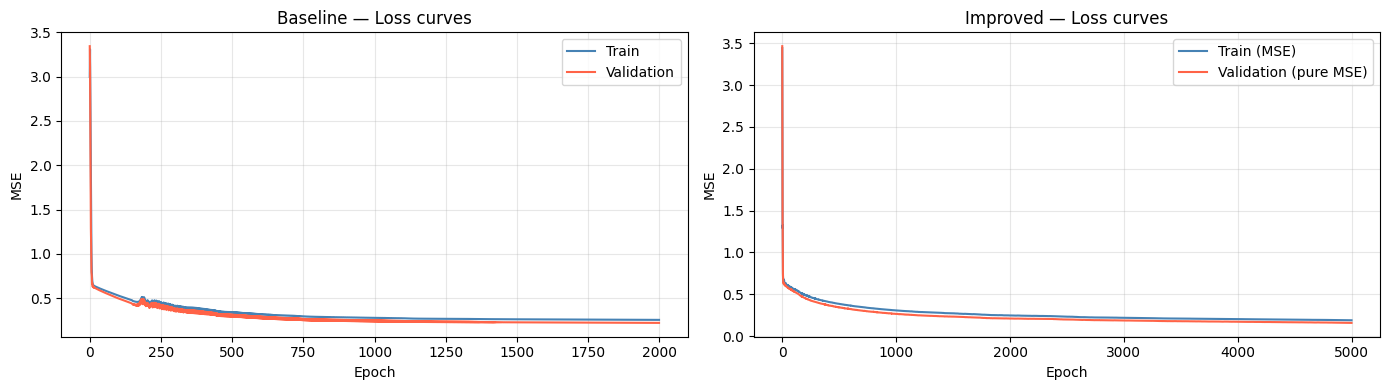

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(tl_base, color='steelblue', label='Train')
axes[0].plot(vl_base, color='tomato',    label='Validation')
axes[0].set_title('Baseline — Loss curves')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('MSE')
axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(tl_imp, color='steelblue', label='Train (MSE)')
axes[1].plot(vl_imp, color='tomato',    label='Validation (pure MSE)')
axes[1].set_title('Improved — Loss curves')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('MSE')
axes[1].legend(); axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


Test MSE  →  Baseline : 0.2641
Test MSE  →  Improved : 0.1991
Improvement           : 24.6%


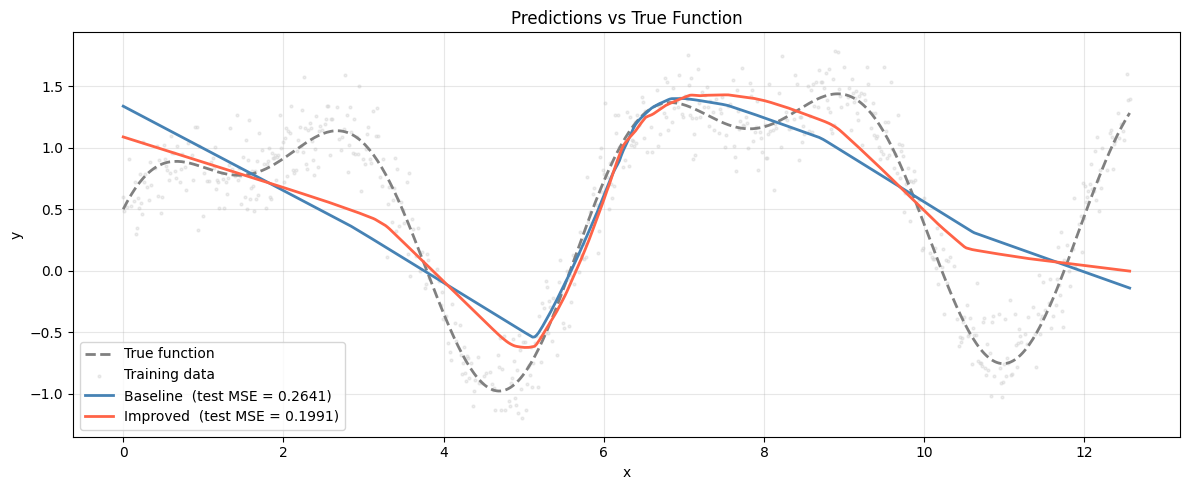

In [42]:
# Test-set evaluation
y_hat_base_test, _ = forward(X_test_n, params_base)
y_hat_imp_test,  _ = forward_dropout(X_test_n, params_imp, training=False)

test_mse_base = mse(y_test, y_hat_base_test)
test_mse_imp  = mse(y_test, y_hat_imp_test)

print(f'Test MSE  →  Baseline : {test_mse_base:.4f}')
print(f'Test MSE  →  Improved : {test_mse_imp:.4f}')
print(f'Improvement           : {(test_mse_base - test_mse_imp) / test_mse_base * 100:.1f}%')

# Prediction curves over the full input range
X_plot_n    = np.linspace(X_train_n.min(), X_train_n.max(), 500).reshape(-1, 1)
X_plot      = X_plot_n * sigma + mu          # denormalise for the x-axis

y_pred_base = forward(X_plot_n, params_base)[0]
y_pred_imp  = forward_dropout(X_plot_n, params_imp, training=False)[0]
y_true_plot = np.sin(X_plot) + 0.5 * np.cos(2 * X_plot) + 0.3 * np.log(X_plot + 1)

plt.figure(figsize=(12, 5))
plt.plot(X_plot, y_true_plot,
         color='gray', linewidth=2, linestyle='--', label='True function')
plt.scatter(X_train, y_train,
            color='lightgray', s=4, alpha=0.4, label='Training data')
plt.plot(X_plot, y_pred_base,
         color='steelblue', linewidth=2,
         label=f'Baseline  (test MSE = {test_mse_base:.4f})')
plt.plot(X_plot, y_pred_imp,
         color='tomato', linewidth=2,
         label=f'Improved  (test MSE = {test_mse_imp:.4f})')
plt.xlabel('x'); plt.ylabel('y')
plt.title('Predictions vs True Function')
plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()


In [43]:
def regression_report(name, y_true, y_pred, params=None):
    mse_val  = np.mean((y_true - y_pred) ** 2)
    rmse_val = np.sqrt(mse_val)
    mae_val  = np.mean(np.abs(y_true - y_pred))
    ss_res   = np.sum((y_true - y_pred) ** 2)
    ss_tot   = np.sum((y_true - y_true.mean()) ** 2)
    r2_val   = 1 - ss_res / ss_tot
    print(f'{name:10s} | MSE={mse_val:.4f}  RMSE={rmse_val:.4f}  MAE={mae_val:.4f}  R²={r2_val:.4f}')

regression_report('Baseline', y_test, y_hat_base_test)
regression_report('Improved', y_test, y_hat_imp_test)

Baseline   | MSE=0.2641  RMSE=0.5139  MAE=0.4139  R²=0.5292
Improved   | MSE=0.1991  RMSE=0.4462  MAE=0.3531  R²=0.6449


> **R² is particularly useful here** because it tells you how much of the signal the model can explain relative to the Gaussian noise — an R² close to $1 - \sigma^2 / \text{Var}(y_{\text{true}})$ would be the maximum theoretical value achievable given the noise you added.

In [44]:
# Theoretical R² ceiling: the best any model can achieve given the noise level.
# A perfect model would predict y_true exactly; its residuals would be pure noise (σ² = 0.2²).
# R²_max = 1 - σ² / Var(y_true)
noise_std = 0.2
r2_max = 1 - noise_std**2 / np.var(y_true)
print(f'Theoretical R² max: {r2_max:.4f}')

Theoretical R² max: 0.9272


# Tuning Process

We need to tune our hyperparameters to get the best out of them. Hyperparameters are:
- Learning rate.
- Momentum beta.
- Mini-batch size.
- No. of hidden units.
- No. of layers.
- Learning rate decay.
- Regularization lambda.
- Activation functions.
- Adam beta1, beta2 & epsilon.
- ...

Its hard to decide which hyperparameter is the most important in a problem. It depends a lot on your problem. One of the ways to tune is to sample a grid with N hyperparameter settings and then try all settings combinations on your problem.

You can use Coarse to fine sampling scheme: when you find some hyperparameters values that give you a better performance - zoom into a smaller region around these values and sample more densely within this space.

---

# Using an Appropriate Scale to Pick Hyperparameters

Let's say you have a specific range for a hyperparameter from "a" to "b". It's better to search for the right ones using the logarithmic scale rather then in linear scale:

    a_log = log(a)  # e.g. a = 0.0001 then a_log = -4
    b_log = log(b)  # e.g. b = 1 then b_log = 0

    r = (a_log - b_log) * np.random.rand() + b_log
    # In the example the range would be from [-4, 0] because rand range [0,1)

    result = 10**r

It uniformly samples values in log scale from [a,b].

If we want to use the last method on exploring on the "momentum beta":

Beta best range is from 0.9 to 0.999.

You should search for 1 - beta in range 0.001 to 0.1 (1 - 0.9 and 1 - 0.999) and then use a = 0.001 and b = 0.1. Then:

    a_log = -3
    b_log = -1

    r = (a_log - b_log) * np.random.rand() + b_log

    beta = 1 - 10**r   # because 1 - beta = 10^r

---

# Hyperparameters Tuning in Practice: Pandas vs. Caviar

Intuitions about hyperparameter settings from one application area may or may not transfer to a different one.

If you don't have much computational resources you can use the "babysitting model":

- Day 0 you might initialize your parameter as random and then start training.
- Then you watch your learning curve gradually decrease over the day.
- And each day you nudge your parameters a little during training.

Called panda approach.

If you have enough computational resources, you can run some models in parallel and at the end of the day(s) you check the results.

Called Caviar approach.

In [45]:
import itertools

# ── Hyperparameter grid ───────────────────────────────────────────────────────
# Architecture and decay_rate fixed; we vary the three most sensitive knobs.
param_grid = {
    'lr0':       [1e-2, 5e-3],
    'lambd':     [1e-3, 5e-3],
    'keep_prob': [0.90, 0.95],
}

keys   = list(param_grid.keys())
combos = list(itertools.product(*param_grid.values()))
print(f'Running grid search: {len(combos)} combinations\n')

grid_results = []
for combo in combos:
    hp = dict(zip(keys, combo))
    _, _, vl, _ = train_improved(
        X_train_n, y_train, X_val_n, y_val,
        layer_sizes=[1, 64, 128, 64, 1],
        epochs=1500, patience=200, decay_rate=3e-4,
        noise_std=0.01, seed=0,
        **hp
    )
    best_val = min(vl)
    grid_results.append({**hp, 'best_val_mse': best_val})
    print(f"lr0={hp['lr0']:.4f}  λ={hp['lambd']:.4f}  keep={hp['keep_prob']:.2f}"
          f"  →  best val MSE: {best_val:.4f}")

grid_df = pd.DataFrame(grid_results).sort_values('best_val_mse').reset_index(drop=True)
print('\n── Results (ranked) ──────────────────────────────────────────')
print(grid_df.to_string(index=False))
print(f'\nBest combo: {grid_df.iloc[0].drop("best_val_mse").to_dict()}  '
      f'→  val MSE {grid_df.iloc[0]["best_val_mse"]:.4f}')

Running grid search: 8 combinations

Final train loss: 0.3564  |  val MSE: 0.3115  |  time: 32.04s
lr0=0.0100  λ=0.0010  keep=0.90  →  best val MSE: 0.3115
Final train loss: 0.2735  |  val MSE: 0.2340  |  time: 32.63s
lr0=0.0100  λ=0.0010  keep=0.95  →  best val MSE: 0.2337
Final train loss: 0.3565  |  val MSE: 0.3116  |  time: 33.31s
lr0=0.0100  λ=0.0050  keep=0.90  →  best val MSE: 0.3116
Final train loss: 0.2734  |  val MSE: 0.2340  |  time: 33.82s
lr0=0.0100  λ=0.0050  keep=0.95  →  best val MSE: 0.2337
Final train loss: 0.4364  |  val MSE: 0.3942  |  time: 38.10s
lr0=0.0050  λ=0.0010  keep=0.90  →  best val MSE: 0.3942
Final train loss: 0.3409  |  val MSE: 0.2997  |  time: 27.03s
lr0=0.0050  λ=0.0010  keep=0.95  →  best val MSE: 0.2992
Final train loss: 0.4366  |  val MSE: 0.3944  |  time: 27.55s
lr0=0.0050  λ=0.0050  keep=0.90  →  best val MSE: 0.3944
Final train loss: 0.3409  |  val MSE: 0.2997  |  time: 26.01s
lr0=0.0050  λ=0.0050  keep=0.95  →  best val MSE: 0.2992

── Results

In [46]:
!pip install optuna -q

Best trial: 0. Best value: 0.327721:   4%|▍         | 1/25 [00:24<09:53, 24.73s/it]

Final train loss: 0.3691  |  val MSE: 0.3280  |  time: 24.72s


Best trial: 0. Best value: 0.327721:   8%|▊         | 2/25 [00:47<09:00, 23.51s/it]

Final train loss: 0.5895  |  val MSE: 0.5641  |  time: 22.65s


Best trial: 0. Best value: 0.327721:  12%|█▏        | 3/25 [01:09<08:20, 22.75s/it]

...

Final train loss: 0.1783  |  val MSE: 0.1487  |  time: 26.35s


Best trial: 23. Best value: 0.144999:  96%|█████████▌| 24/25 [09:33<00:23, 23.48s/it]

Final train loss: 0.1753  |  val MSE: 0.1458  |  time: 23.42s


Best trial: 23. Best value: 0.144999: 100%|██████████| 25/25 [09:57<00:00, 23.90s/it]

Final train loss: 0.2248  |  val MSE: 0.1933  |  time: 23.75s

── Optuna best result ──────────────────────────────────────
Best val MSE : 0.1450
Best params  : {'lr0': 0.03151609412642366, 'lambd': 0.00012826871157868043, 'keep_prob': 0.9748876774269227, 'decay_rate': 0.000263985980885307}


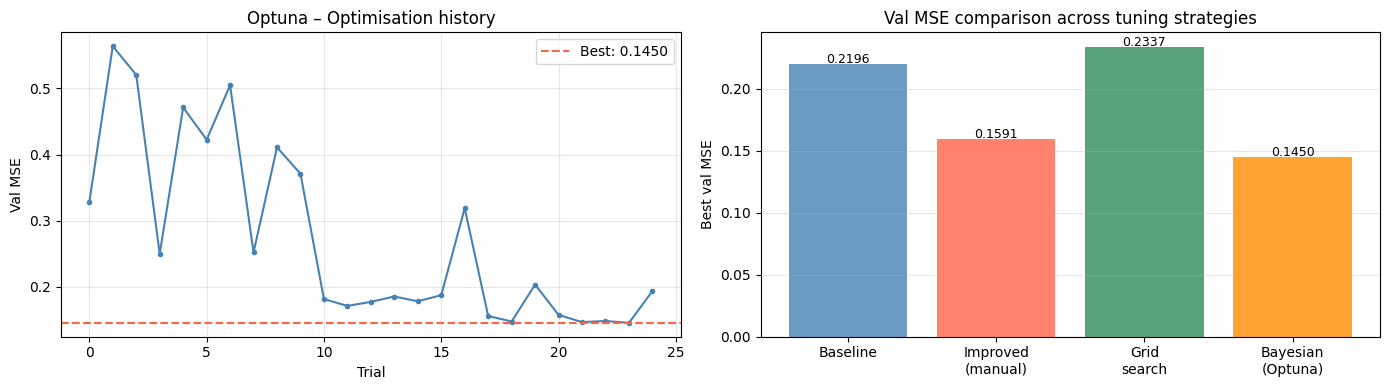

In [47]:
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(trial):
    lr0       = trial.suggest_float('lr0',        1e-3, 5e-2, log=True)
    lambd     = trial.suggest_float('lambd',       1e-4, 1e-2, log=True)
    keep_prob = trial.suggest_float('keep_prob',   0.80, 1.00)
    decay     = trial.suggest_float('decay_rate',  1e-4, 1e-3, log=True)

    _, _, vl, _ = train_improved(
        X_train_n, y_train, X_val_n, y_val,
        layer_sizes=[1, 64, 128, 64, 1],
        epochs=1500, patience=200,
        lr0=lr0, lambd=lambd, keep_prob=keep_prob,
        decay_rate=decay, noise_std=0.01, seed=0
    )
    return min(vl)

study = optuna.create_study(direction='minimize',
                             sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(objective, n_trials=25, show_progress_bar=True)

print('\n── Optuna best result ──────────────────────────────────────')
print(f'Best val MSE : {study.best_value:.4f}')
print('Best params  :', study.best_params)

# ── Comparison bar chart ──────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

trials_df = study.trials_dataframe()
axes[0].plot(trials_df['value'], color='steelblue', marker='o', markersize=3)
axes[0].axhline(study.best_value, color='tomato', linestyle='--',
                label=f'Best: {study.best_value:.4f}')
axes[0].set_xlabel('Trial'); axes[0].set_ylabel('Val MSE')
axes[0].set_title('Optuna – Optimisation history')
axes[0].legend(); axes[0].grid(True, alpha=0.3)

labels = ['Baseline', 'Improved\n(manual)', 'Grid\nsearch', 'Bayesian\n(Optuna)']
values = [min(vl_base), min(vl_imp), grid_df['best_val_mse'].min(), study.best_value]
colors = ['steelblue', 'tomato', 'seagreen', 'darkorange']
bars   = axes[1].bar(labels, values, color=colors, alpha=0.8)
axes[1].set_ylabel('Best val MSE')
axes[1].set_title('Val MSE comparison across tuning strategies')
axes[1].grid(True, alpha=0.3, axis='y')
for bar, v in zip(bars, values):
    axes[1].text(bar.get_x() + bar.get_width() / 2, v + 0.001, f'{v:.4f}',
                 ha='center', fontsize=9)
plt.tight_layout()
plt.show()

# Normalizing Activations in a Network

In the rise of deep learning, one of the most important ideas has been an algorithm called batch normalization, created by two researchers, Sergey Ioffe and Christian Szegedy.

Batch Normalization speeds up learning.

Before we normalized input by subtracting the mean and dividing by variance. This helped a lot for the shape of the cost function and for reaching the minimum point faster.

The question is: for any hidden layer can we normalize A[l] to train W[l+1], b[l+1] faster? This is what batch normalization is about.

There are some debates in the deep learning literature about whether you should normalize values before the activation function Z[l] or after applying the activation function A[l]. In practice, normalizing Z[l] is done much more often and that is what Andrew Ng presents.

---

# Algorithm

Given:
Z[l] = [z(1), ..., z(m)], i = 1 to m (for each input)

    mean = 1/m * sum(z[i])

    variance = 1/m * sum((z[i] - mean)**2)

    Z_norm[i] = (z[i] - mean) / np.sqrt(variance + epsilon)
    # add epsilon for numerical stability if variance = 0

Forcing the inputs to a distribution with zero mean and variance of 1.

    Z_tilde[i] = gamma * Z_norm[i] + beta

To make inputs belong to other distribution (with other mean and variance).

gamma and beta are learnable parameters of the model.

Making the NN learn the distribution of the outputs.

Note:
if gamma = sqrt(variance + epsilon) and beta = mean then:

    Z_tilde[i] = z[i]

---

# Why Does Batch Normalization Work?

The first reason is the same reason as why we normalize X.

The second reason is that batch normalization reduces the problem of input values changing (shifting).

Batch normalization does some regularization:

Each mini batch is scaled by the mean/variance computed of that mini-batch.

This adds some noise to the values Z[l] within that mini batch. So similar to dropout it adds some noise to each hidden layer's activations.

This has a slight regularization effect.

Using bigger size of the mini-batch you are reducing noise and therefore regularization effect.

Don't rely on batch normalization as a regularization. It's intended for normalization of hidden units, activations and therefore speeding up learning. For regularization use other regularization techniques (L2 or dropout).

---

# Batch Normalization at Test Time

When we train a NN with Batch normalization, we compute the mean and the variance of the mini-batch.

In testing we might need to process examples one at a time. The mean and the variance of one example won't make sense.

We have to compute an estimated value of mean and variance to use it in testing time.

We can use the weighted average across the mini-batches.

We will use the estimated values of the mean and variance to test.

This method is also sometimes called "Running average".

In practice most often you will use a deep learning framework and it will contain some default implementation of doing such a thing.

In [48]:
EPS = 1e-8

# ── BN primitives ─────────────────────────────────────────────────────────────
def bn_forward(Z, gamma, beta, running_mean, running_var,
               training=True, momentum=0.9):
    if training:
        mean    = Z.mean(axis=0, keepdims=True)
        var     = Z.var(axis=0,  keepdims=True)
        Z_norm  = (Z - mean) / np.sqrt(var + EPS)
        Z_tilde = gamma * Z_norm + beta
        running_mean[:] = momentum * running_mean + (1 - momentum) * mean
        running_var[:]  = momentum * running_var  + (1 - momentum) * var
        cache = (Z, Z_norm, mean, var, gamma)
    else:
        Z_norm  = (Z - running_mean) / np.sqrt(running_var + EPS)
        Z_tilde = gamma * Z_norm + beta
        cache   = None
    return Z_tilde, cache


def bn_backward(dZ_tilde, cache):
    """Closed-form BN gradient (Ioffe & Szegedy)."""
    Z, Z_norm, mean, var, gamma = cache
    m       = Z.shape[0]
    dgamma  = (dZ_tilde * Z_norm).sum(axis=0, keepdims=True)
    dbeta   = dZ_tilde.sum(axis=0, keepdims=True)
    dZ_norm = dZ_tilde * gamma
    std_inv = 1.0 / np.sqrt(var + EPS)
    dZ = (std_inv / m) * (
        m * dZ_norm
        - dZ_norm.sum(axis=0, keepdims=True)
        - Z_norm * (dZ_norm * Z_norm).sum(axis=0, keepdims=True)
    )
    return dZ, dgamma, dbeta

In [49]:
# ── BN-aware network ──────────────────────────────────────────────────────────
def init_bn_params(layer_sizes):
    bn = {}
    for i in range(1, len(layer_sizes) - 1):   # hidden layers only
        n = layer_sizes[i]
        bn[f'gamma{i}'] = np.ones((1, n))
        bn[f'beta{i}']  = np.zeros((1, n))
        bn[f'rm{i}']    = np.zeros((1, n))      # running mean
        bn[f'rv{i}']    = np.zeros((1, n))      # running variance
    return bn


def forward_bn(X, params, bn, training=True):
    cache = {'a0': X}
    a, n_layers = X, len(params) // 2
    for i in range(1, n_layers):                # hidden — BN then ReLU
        z = a @ params[f'W{i}'] + params[f'b{i}']
        zt, bn_cache = bn_forward(z, bn[f'gamma{i}'], bn[f'beta{i}'],
                                  bn[f'rm{i}'], bn[f'rv{i}'], training=training)
        a = relu(zt)
        cache.update({f'z{i}': z, f'zt{i}': zt, f'bn{i}': bn_cache, f'a{i}': a})
    i = n_layers                                # output — linear, no BN
    z = a @ params[f'W{i}'] + params[f'b{i}']
    cache[f'z{i}'] = cache[f'a{i}'] = z
    return z, cache


def backward_bn(y, y_hat, params, cache, bn):
    m, n_layers = y.shape[0], len(params) // 2
    grads, bn_grads = {}, {}
    delta = -(y - y_hat) / m
    for i in range(n_layers, 0, -1):
        grads[f'dW{i}'] = cache[f'a{i-1}'].T @ delta
        grads[f'db{i}'] = delta.sum(axis=0, keepdims=True)
        if i > 1:
            # backprop through ReLU on z_tilde, then through BN to reach z
            delta = delta @ params[f'W{i}'].T * relu_deriv(cache[f'zt{i-1}'])
            delta, dgamma, dbeta = bn_backward(delta, cache[f'bn{i-1}'])
            bn_grads[f'dgamma{i-1}'] = dgamma
            bn_grads[f'dbeta{i-1}']  = dbeta
    return grads, bn_grads

In [50]:
def update_bn_params(bn, bn_grads, lr):
    for key, grad in bn_grads.items():
        bn[key[1:]] -= lr * grad        # 'dgamma1' → 'gamma1'
    return bn


def train_bn(X_tr, y_tr, X_v, y_v, layer_sizes, lr=1e-2, epochs=2000, seed=0):
    params = init_params(layer_sizes, seed=seed)
    bn     = init_bn_params(layer_sizes)
    tl, vl = [], []
    start  = time.time()
    for _ in range(epochs):
        y_hat, cache = forward_bn(X_tr, params, bn, training=True)
        grads, bg    = backward_bn(y_tr, y_hat, params, cache, bn)
        params       = update_params(params, grads, lr)
        bn           = update_bn_params(bn, bg, lr)
        tl.append(mse(y_tr, y_hat))
        y_hat_v, _   = forward_bn(X_v, params, bn, training=False)
        vl.append(mse(y_v, y_hat_v))
    elapsed = time.time() - start
    print(f'Final train MSE: {tl[-1]:.4f}  |  val MSE: {vl[-1]:.4f}  |  time: {elapsed:.2f}s')
    return params, bn, tl, vl

In [51]:
# ── Train ─────────────────────────────────────────────────────────────────────
layer_sizes = [1, 64, 128, 64, 1]
print('Training with Batch Normalisation…')
params_bn, bn, tl_bn, vl_bn = train_bn(
    X_train_n, y_train, X_val_n, y_val,
    layer_sizes=layer_sizes, lr=1e-2, epochs=2000, seed=0
)

y_hat_bn_test, _ = forward_bn(X_test_n, params_bn, bn, training=False)
test_mse_bn = mse(y_test, y_hat_bn_test)
print()
regression_report('BN', y_test, y_hat_bn_test)

Training with Batch Normalisation…
Final train MSE: 0.0363  |  val MSE: 0.0354  |  time: 41.24s

BN         | MSE=0.0425  RMSE=0.2062  MAE=0.1637  R²=0.9242


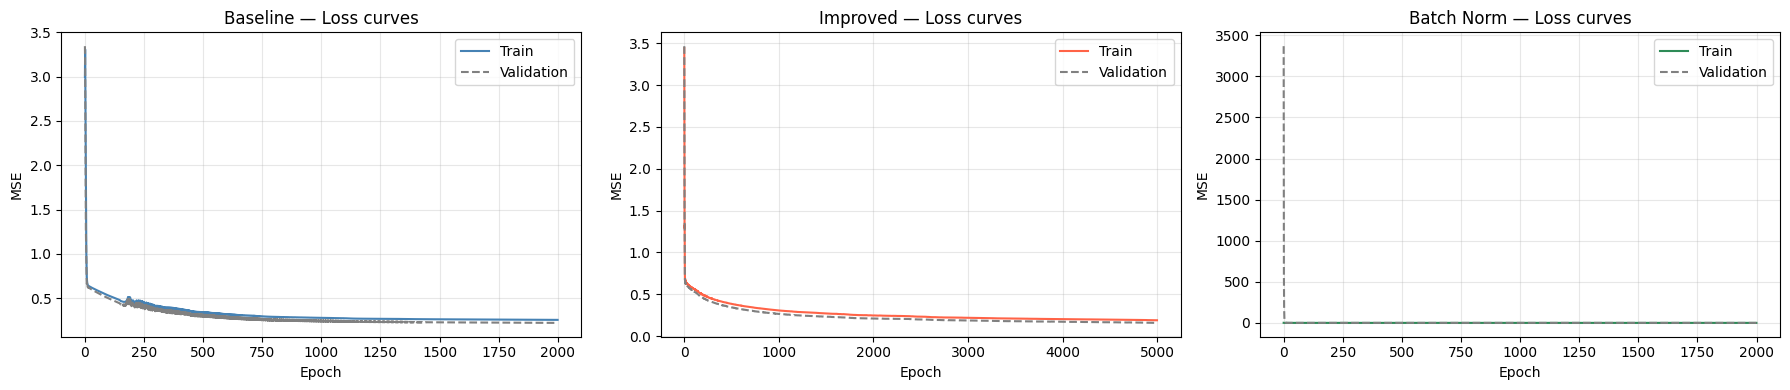

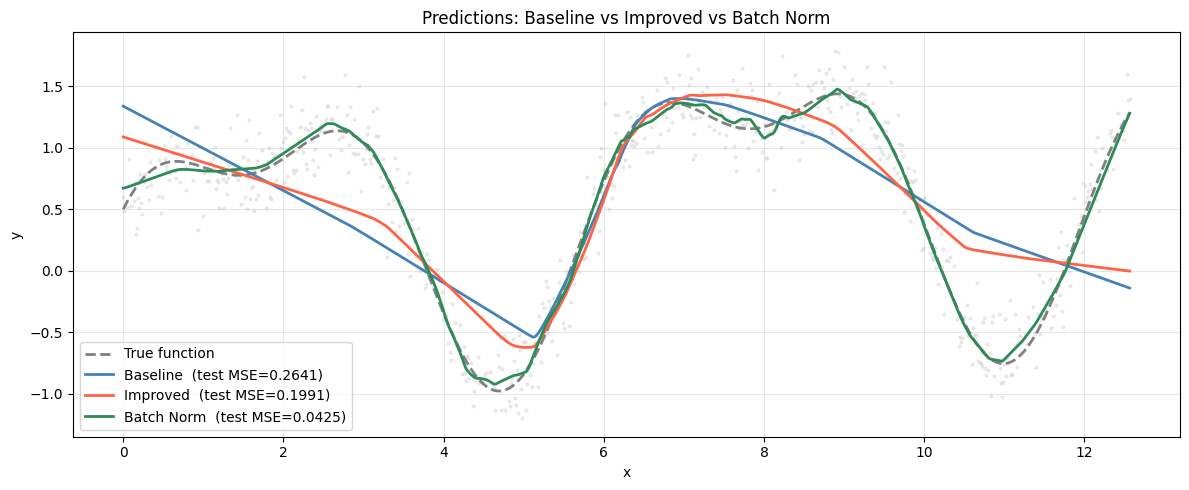

In [52]:
# ── Loss curves comparison ────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, tl, vl, title, color in zip(
        axes,
        [tl_base, tl_imp,  tl_bn],
        [vl_base, vl_imp,  vl_bn],
        ['Baseline', 'Improved', 'Batch Norm'],
        ['steelblue', 'tomato', 'seagreen']):
    ax.plot(tl, color=color, label='Train')
    ax.plot(vl, color='gray', linestyle='--', label='Validation')
    ax.set_title(f'{title} — Loss curves')
    ax.set_xlabel('Epoch'); ax.set_ylabel('MSE')
    ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

# ── Prediction curves ─────────────────────────────────────────────────────────
X_plot_n    = np.linspace(X_train_n.min(), X_train_n.max(), 500).reshape(-1, 1)
X_plot      = X_plot_n * sigma + mu
y_true_plot = np.sin(X_plot) + 0.5 * np.cos(2 * X_plot) + 0.3 * np.log(X_plot + 1)

plt.figure(figsize=(12, 5))
plt.plot(X_plot, y_true_plot, '--', color='gray', lw=2, label='True function')
plt.scatter(X_train, y_train, color='lightgray', s=4, alpha=0.4)
plt.plot(X_plot, forward(X_plot_n, params_base)[0],
         color='steelblue', lw=2, label=f'Baseline  (test MSE={test_mse_base:.4f})')
plt.plot(X_plot, forward_dropout(X_plot_n, params_imp, training=False)[0],
         color='tomato',    lw=2, label=f'Improved  (test MSE={test_mse_imp:.4f})')
plt.plot(X_plot, forward_bn(X_plot_n, params_bn, bn, training=False)[0],
         color='seagreen',  lw=2, label=f'Batch Norm  (test MSE={test_mse_bn:.4f})')
plt.xlabel('x'); plt.ylabel('y')
plt.title('Predictions: Baseline vs Improved vs Batch Norm')
plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

### Why BN outperforms everything else on this problem

Probably is because it use the entire training set as a single batch (full-batch BN). With normal mini-batches (e.g. batch size 32), BN introduces noise because the statistics of each mini-batch fluctuate. Here, however, BN calculates the exact mean and variance of the 700 training samples at every step → perfect normalisation, no noise, and gradients that are always well-conditioned.
The main challenge is to propagate gradients through four layers and BN solves exactly this

---

## Satisfying vs Optimizing Metric

Sometimes it is hard to reduce everything to a single evaluation metric. Ex:

| Classifier | F1 Score | Running Time |
|-----------|----------|--------------|
| A         | 90%      | 80 ms        |
| B         | 94%      | 1500 ms      |

- **Maximize** $F1$  → *optimizing metric*  
- **subject to** $running\ time < 100ms$ → *satisficing metric*

### General Rule

- **Maximize** $1$ metric  
- **subject to** $N-1$ constraints  

---

## When Metrics Fail (Cat Classification Example)

### Results

| Algorithm   | Classification Error |
|------------|---------------------  |
| A          | 3% (but many porn images misclassified as cats) |
| B          | 5%                  |

Even though **Algorithm A** has better error, users prefer **B**. This means the metric is flawed and must be changed.

$$
OldMetric = \frac{1}{m} \sum_{i=1}^{m} (y_{pred}^{(i)} \neq y^{(i)})
$$

where:
- $m$ = number of examples in the dev set 

$$
NewMetric = \frac{1}{\sum_i w^{(i)}} \sum_{i=1}^{m} w^{(i)} \cdot (y_{pred}^{(i)} \neq y^{(i)})
$$

where:

- $w^{(i)} = 1$ if $x^{(i)}$ is **not porn**
- $w^{(i)} = 10$ if $x^{(i)}$ is **porn**

So if doing well on your **metric + dev/test set** does **not** correspond to doing well in your real application: change your metric and/or dev/test set

### About dataset

An old way of splitting the data was 70% training, 30% test or 60% training, 20% dev, 20% test. The old way was valid for a number of examples ~ <100000. In the modern deep learning if you have a million or more examples a reasonable split would be 98% training, 1% dev, 1% test.

Dev and test sets have to come from the same distribution. Choose dev set and test set to reflect data you expect to get in the future and consider important to do well on.
Setting up the dev set, as well as the validation metric is really defining what target you want to aim at.





# https://www.cs.cornell.edu/courses/cs4780/2024sp/lectures/lecturenote12.html

# https://github.com/amanchadha/coursera-deep-learning-specialization/

# https://aman.ai/

# https://en.wikipedia.org/wiki/Empirical_risk_minimization#Background